CONVERSÃO DE FREQUÊNCIAS
f (Hz)      fs (Hz)     fn (ciclos/amostra)     ω (rad/amostra)       Dentro de Nyquist   
50.00       1000.00     0.0500                  0.3142                Sim                 
100.00      1000.00     0.1000                  0.6283                Sim                 
250.00      1000.00     0.2500                  1.5708                Sim                 
400.00      1000.00     0.4000                  2.5133                Sim                 
600.00      1000.00     0.6000                  3.7699                Não                 


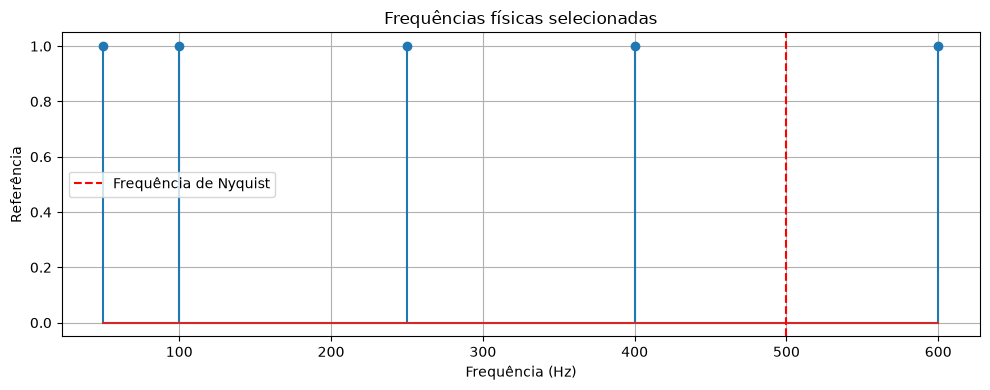

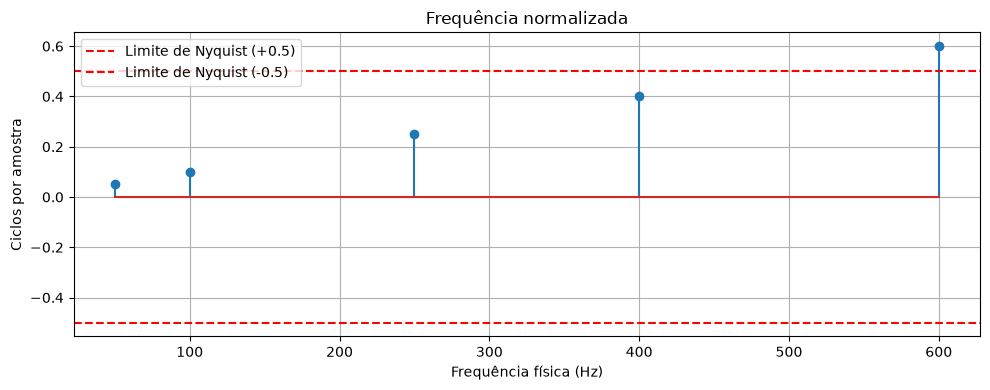

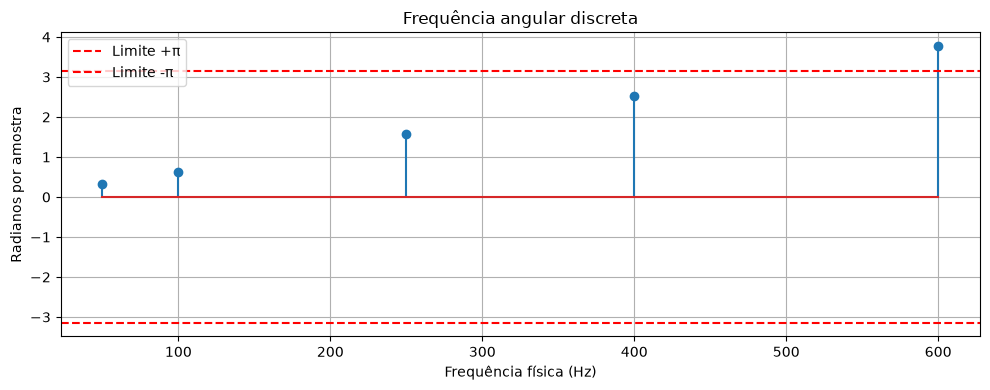

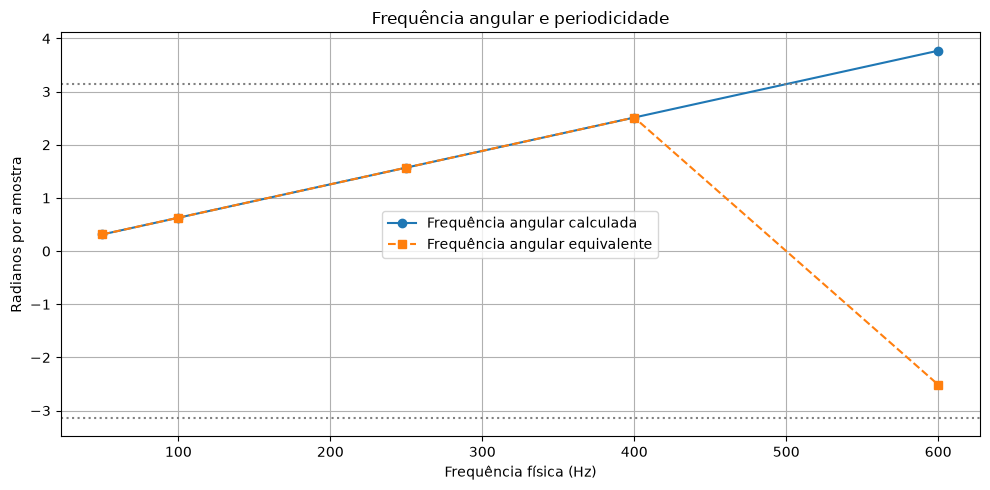


INFLUÊNCIA DA FREQUÊNCIA DE AMOSTRAGEM
fs (Hz)        f (Hz)         fn (ciclos/amostra)      ω (rad/amostra)     
200            100            0.5000                   3.1416              
500            100            0.2000                   1.2566              
1000           100            0.1000                   0.6283              
2000           100            0.0500                   0.3142              
4000           100            0.0250                   0.1571              

Simulação concluída!


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

# Frequência de amostragem (Hz)
fs = 1000

# Diferentes frequências físicas para análise (Hz)
frequencias = [50, 100, 250, 400, 600]


# ============================================================
# 2. CONVERSÃO ENTRE AS FREQUÊNCIAS
# ============================================================

def converter_frequencia(f, fs):

    # Frequência normalizada (ciclos/amostra)
    fn = f / fs

    # Frequência angular (rad/amostra)
    omega = 2 * np.pi * fn

    # Frequência angular equivalente no intervalo [-pi, pi)
    omega_principal = np.angle(np.exp(1j * omega))

    # Frequência normalizada equivalente
    fn_principal = omega_principal / (2 * np.pi)

    return fn, omega, fn_principal, omega_principal


# ============================================================
# 3. APRESENTAÇÃO DOS RESULTADOS
# ============================================================

print("CONVERSÃO DE FREQUÊNCIAS")
print("=" * 100)

print(
    f"{'f (Hz)':<12}"
    f"{'fs (Hz)':<12}"
    f"{'fn (ciclos/amostra)':<24}"
    f"{'ω (rad/amostra)':<22}"
    f"{'Dentro de Nyquist':<20}"
)

resultados = []

for f in frequencias:

    fn, omega, fn_p, omega_p = converter_frequencia(f, fs)

    # Verificação do critério de Nyquist
    valido = f <= fs / 2

    resultados.append((f, fn, omega, fn_p, omega_p))

    print(
        f"{f:<12.2f}"
        f"{fs:<12.2f}"
        f"{fn:<24.4f}"
        f"{omega:<22.4f}"
        f"{'Sim' if valido else 'Não':<20}"
    )


# ============================================================
# 4. GRÁFICO DA FREQUÊNCIA EM HERTZ
# ============================================================

f_valores = [r[0] for r in resultados]

plt.figure(figsize=(10, 4))

plt.stem(f_valores, np.ones(len(f_valores)))

plt.axvline(
    fs / 2,
    color='red',
    linestyle='--',
    label='Frequência de Nyquist'
)

plt.title("Frequências físicas selecionadas")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Referência")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 5. GRÁFICO DA FREQUÊNCIA NORMALIZADA
# ============================================================

fn_valores = [r[1] for r in resultados]

plt.figure(figsize=(10, 4))

plt.stem(f_valores, fn_valores)

plt.axhline(
    0.5,
    color='red',
    linestyle='--',
    label='Limite de Nyquist (+0.5)'
)

plt.axhline(
    -0.5,
    color='red',
    linestyle='--',
    label='Limite de Nyquist (-0.5)'
)

plt.title("Frequência normalizada")
plt.xlabel("Frequência física (Hz)")
plt.ylabel("Ciclos por amostra")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. GRÁFICO DA FREQUÊNCIA ANGULAR
# ============================================================

omega_valores = [r[2] for r in resultados]

plt.figure(figsize=(10, 4))

plt.stem(f_valores, omega_valores)

plt.axhline(
    np.pi,
    color='red',
    linestyle='--',
    label='Limite +π'
)

plt.axhline(
    -np.pi,
    color='red',
    linestyle='--',
    label='Limite -π'
)

plt.title("Frequência angular discreta")
plt.xlabel("Frequência física (Hz)")
plt.ylabel("Radianos por amostra")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. COMPARAÇÃO ENTRE FREQUÊNCIA ORIGINAL E EQUIVALENTE
# ============================================================

omega_principal = [r[4] for r in resultados]

plt.figure(figsize=(10, 5))

plt.plot(
    f_valores,
    omega_valores,
    'o-',
    label='Frequência angular calculada'
)

plt.plot(
    f_valores,
    omega_principal,
    's--',
    label='Frequência angular equivalente'
)

plt.axhline(np.pi, color='gray', linestyle=':')
plt.axhline(-np.pi, color='gray', linestyle=':')

plt.title("Frequência angular e periodicidade")
plt.xlabel("Frequência física (Hz)")
plt.ylabel("Radianos por amostra")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. TESTE COM DIFERENTES FREQUÊNCIAS DE AMOSTRAGEM
# ============================================================

frequencia_sinal = 100

frequencias_amostragem = [200, 500, 1000, 2000, 4000]

print("\nINFLUÊNCIA DA FREQUÊNCIA DE AMOSTRAGEM")
print("=" * 75)

print(
    f"{'fs (Hz)':<15}"
    f"{'f (Hz)':<15}"
    f"{'fn (ciclos/amostra)':<25}"
    f"{'ω (rad/amostra)':<20}"
)

for taxa in frequencias_amostragem:

    fn, omega, fn_p, omega_p = converter_frequencia(
        frequencia_sinal, taxa
    )

    print(
        f"{taxa:<15}"
        f"{frequencia_sinal:<15}"
        f"{fn:<25.4f}"
        f"{omega:<20.4f}"
    )


print("\nSimulação concluída!")
